<a href="https://colab.research.google.com/github/Alka-Maharana/customer-segmentation-analytics/blob/main/Customer_Segmentation_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
data = urllib.request.urlopen(url).read()

with zipfile.ZipFile(io.BytesIO(data)) as z:
    filename = next(f for f in z.namelist() if f.endswith(".xlsx"))
    df = pd.read_excel(z.open(filename))

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Dataset loaded successfully!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:

# Clean transaction data
df = df.dropna(subset=["CustomerID"]).copy()

df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Calculate customer-level RFM metrics
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("Cleaned transactions:", len(df))
print("Unique customers:", rfm["CustomerID"].nunique())
display(rfm.head())


Cleaned transactions: 397884
Unique customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [4]:

# Score customers from 1 to 4 using RFM metrics
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4, labels=[4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4, labels=[1, 2, 3, 4]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4, labels=[1, 2, 3, 4]
).astype(int)

def segment_customer(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"
    elif row["R_Score"] >= 3 and row["M_Score"] >= 3:
        return "High-Value Active"
    elif row["R_Score"] <= 2:
        return "At-Risk Customers"
    else:
        return "Other Customers"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

print("Customer segmentation completed!")
display(rfm.head())
print("\nCustomers by segment:")
display(rfm["Segment"].value_counts().to_frame("Customer Count"))


Customer segmentation completed!


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,Segment
0,12346,326,1,77183.60,1,1,4,At-Risk Customers
1,12347,2,7,4310.00,4,4,4,Loyal Customers
2,12348,75,4,1797.24,2,3,4,At-Risk Customers
3,12349,19,1,1757.55,3,1,4,High-Value Active
4,12350,310,1,334.40,1,1,2,At-Risk Customers



Customers by segment:


,Customer Count
Segment,
At-Risk Customers,2169
Loyal Customers,1514
Other Customers,520
High-Value Active,135


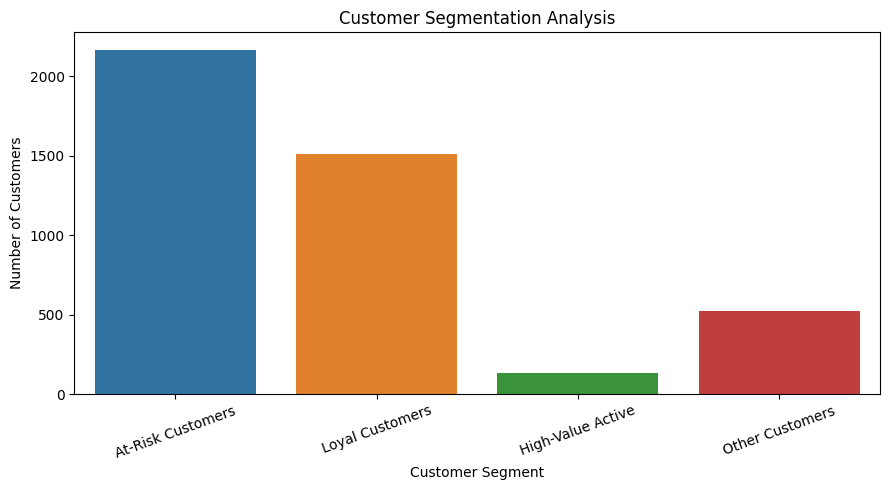

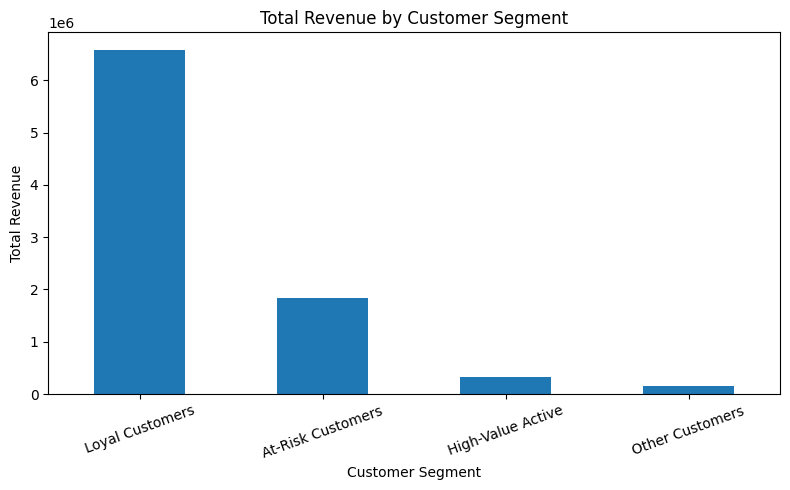

In [5]:

# Customer count by segment
plt.figure(figsize=(9, 5))
sns.countplot(data=rfm, x="Segment", hue="Segment", legend=False)
plt.title("Customer Segmentation Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Revenue by customer segment
segment_revenue = rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
segment_revenue.plot(kind="bar")
plt.title("Total Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [6]:

# Key business insights
total_customers = len(rfm)
total_revenue = rfm["Monetary"].sum()
avg_spending = rfm["Monetary"].mean()
top_segment = rfm["Segment"].value_counts().idxmax()
top_revenue_segment = segment_revenue.idxmax()

print("CUSTOMER SEGMENTATION: KEY FINDINGS")
print("-" * 40)
print(f"Total customers analyzed: {total_customers:,}")
print(f"Total revenue analyzed: {total_revenue:,.2f}")
print(f"Average customer spend: {avg_spending:,.2f}")
print(f"Largest customer segment: {top_segment}")
print(f"Highest-revenue segment: {top_revenue_segment}")

print("\nBUSINESS RECOMMENDATIONS")
print("- Retain loyal customers through personalized engagement.")
print("- Investigate at-risk customers for potential re-engagement.")
print("- Examine high-value customers to understand their purchasing patterns.")


CUSTOMER SEGMENTATION: KEY FINDINGS
----------------------------------------
Total customers analyzed: 4,338
Total revenue analyzed: 8,911,407.90
Average customer spend: 2,054.27
Largest customer segment: At-Risk Customers
Highest-revenue segment: Loyal Customers

BUSINESS RECOMMENDATIONS
- Retain loyal customers through personalized engagement.
- Investigate at-risk customers for potential re-engagement.
- Examine high-value customers to understand their purchasing patterns.


In [7]:

# Key business insights
total_customers = len(rfm)
total_revenue = rfm["Monetary"].sum()
avg_spending = rfm["Monetary"].mean()
top_segment = rfm["Segment"].value_counts().idxmax()
top_revenue_segment = segment_revenue.idxmax()

print("CUSTOMER SEGMENTATION: KEY FINDINGS")
print("-" * 40)
print(f"Total customers analyzed: {total_customers:,}")
print(f"Total revenue analyzed: {total_revenue:,.2f}")
print(f"Average customer spend: {avg_spending:,.2f}")
print(f"Largest customer segment: {top_segment}")
print(f"Highest-revenue segment: {top_revenue_segment}")

print("\nBUSINESS RECOMMENDATIONS")
print("- Retain loyal customers through personalized engagement.")
print("- Investigate at-risk customers for potential re-engagement.")
print("- Examine high-value customers to understand their purchasing patterns.")


CUSTOMER SEGMENTATION: KEY FINDINGS
----------------------------------------
Total customers analyzed: 4,338
Total revenue analyzed: 8,911,407.90
Average customer spend: 2,054.27
Largest customer segment: At-Risk Customers
Highest-revenue segment: Loyal Customers

BUSINESS RECOMMENDATIONS
- Retain loyal customers through personalized engagement.
- Investigate at-risk customers for potential re-engagement.
- Examine high-value customers to understand their purchasing patterns.
